# Figure 2

In [1]:
import os
import sys
sys.path.insert(0, "../lib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["pdf.fonttype"] = 42   # keep text editable in Illustrator
plt.rcParams["ps.fonttype"] = 42

from data_io import load_cells, load_traces, load_roi_coordinates
cells = load_cells()
FI = 0.806                    # s per volume
DATASETS = ["P2P3", "P6P7"]
from qc import ACTIVITY_THRESH_DFF
from figure_panels import (cell_counts_by_plane, max_dff_scatter_with_qc_pie, n_subpeaks_vs_max_dff,
                           activity_space_examples)
from correlation_panels import load_animal_group, pairwise_r_distributions
qc = pd.read_parquet("../data/cell_qc.parquet")
feat_df = pd.read_parquet("../data/cell_features.parquet")
coords = load_roi_coordinates()
DATASET = "P2P3"
FIG = "../figures/Fig2"
os.makedirs(FIG, exist_ok=True)
traces = load_traces(DATASET)

## Panel A

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


{'n_included': 1234, 'n_excluded': 11, 'pct_active': 99.11646586345381}

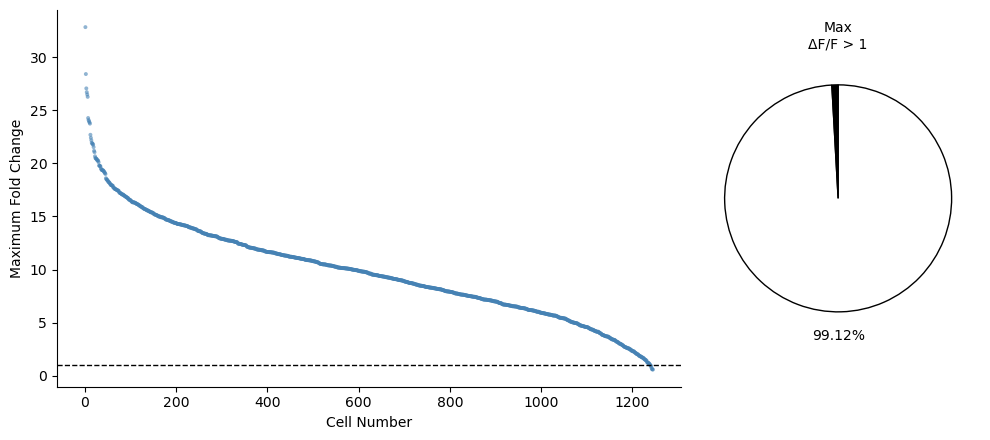

In [2]:
fig, stats = max_dff_scatter_with_qc_pie(qc, DATASET, ACTIVITY_THRESH_DFF, f"{FIG}/Fig2A_max_dff_and_activity_pie",
                                         ylabel="Maximum Fold Change")
stats

## Panels B–C

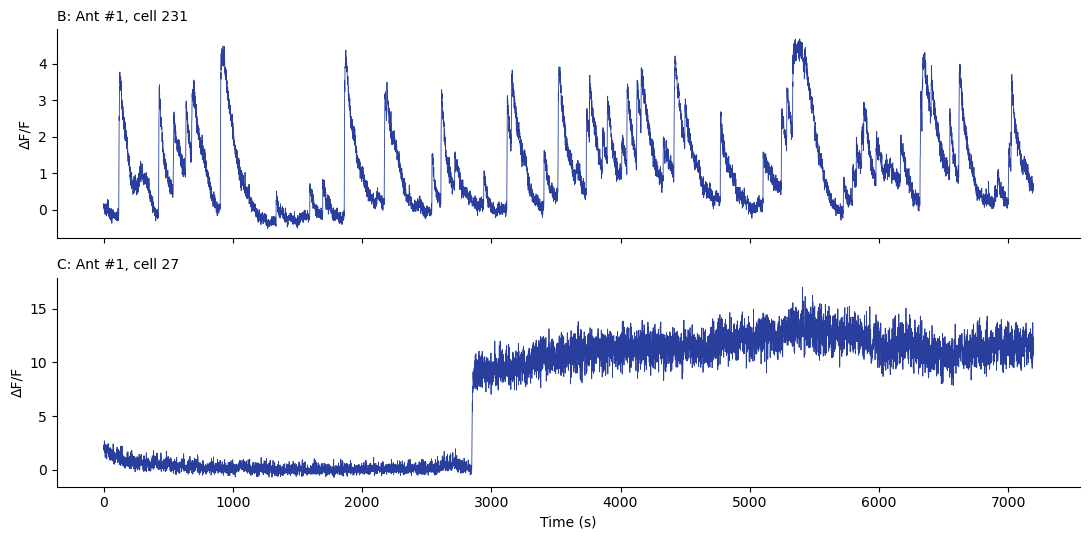

In [3]:
EXAMPLE_RAW_CELLS = {"B": 231, "C": 27}
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, (panel, cid) in zip(axes, EXAMPLE_RAW_CELLS.items()):
    row = cells[cells.cell_id == cid].iloc[0]
    tr = traces[row.row_in_dataset]
    ax.plot(np.arange(len(tr)) * FI, tr, color="#2a3f9d", linewidth=0.6)
    ax.set_title(f"{panel}: {row.ant}, cell {cid}", fontsize=10, loc="left")
    ax.set_ylabel("ΔF/F"); ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig(f"{FIG}/Fig2BC_example_raw_traces.pdf", bbox_inches="tight")
plt.savefig(f"{FIG}/Fig2BC_example_raw_traces.eps", bbox_inches="tight")

## Panel D

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


r = -0.425, R^2 = 0.181, p = 2.59e-55, n = 1234


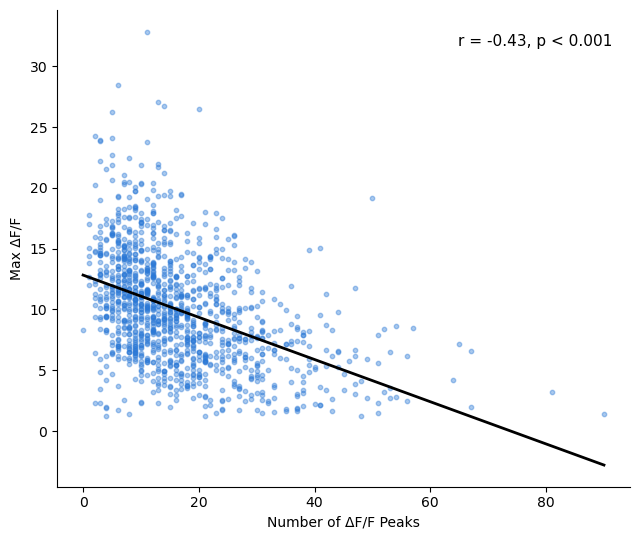

In [4]:
fig, fit = n_subpeaks_vs_max_dff(feat_df, DATASET, f"{FIG}/Fig2D_n_peaks_vs_max_dff")
print(f"r = {fit.rvalue:.3f}, R^2 = {fit.rvalue**2:.3f}, p = {fit.pvalue:.2e}, n = {(feat_df.dataset == DATASET).sum()}")

## Panels E–F

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


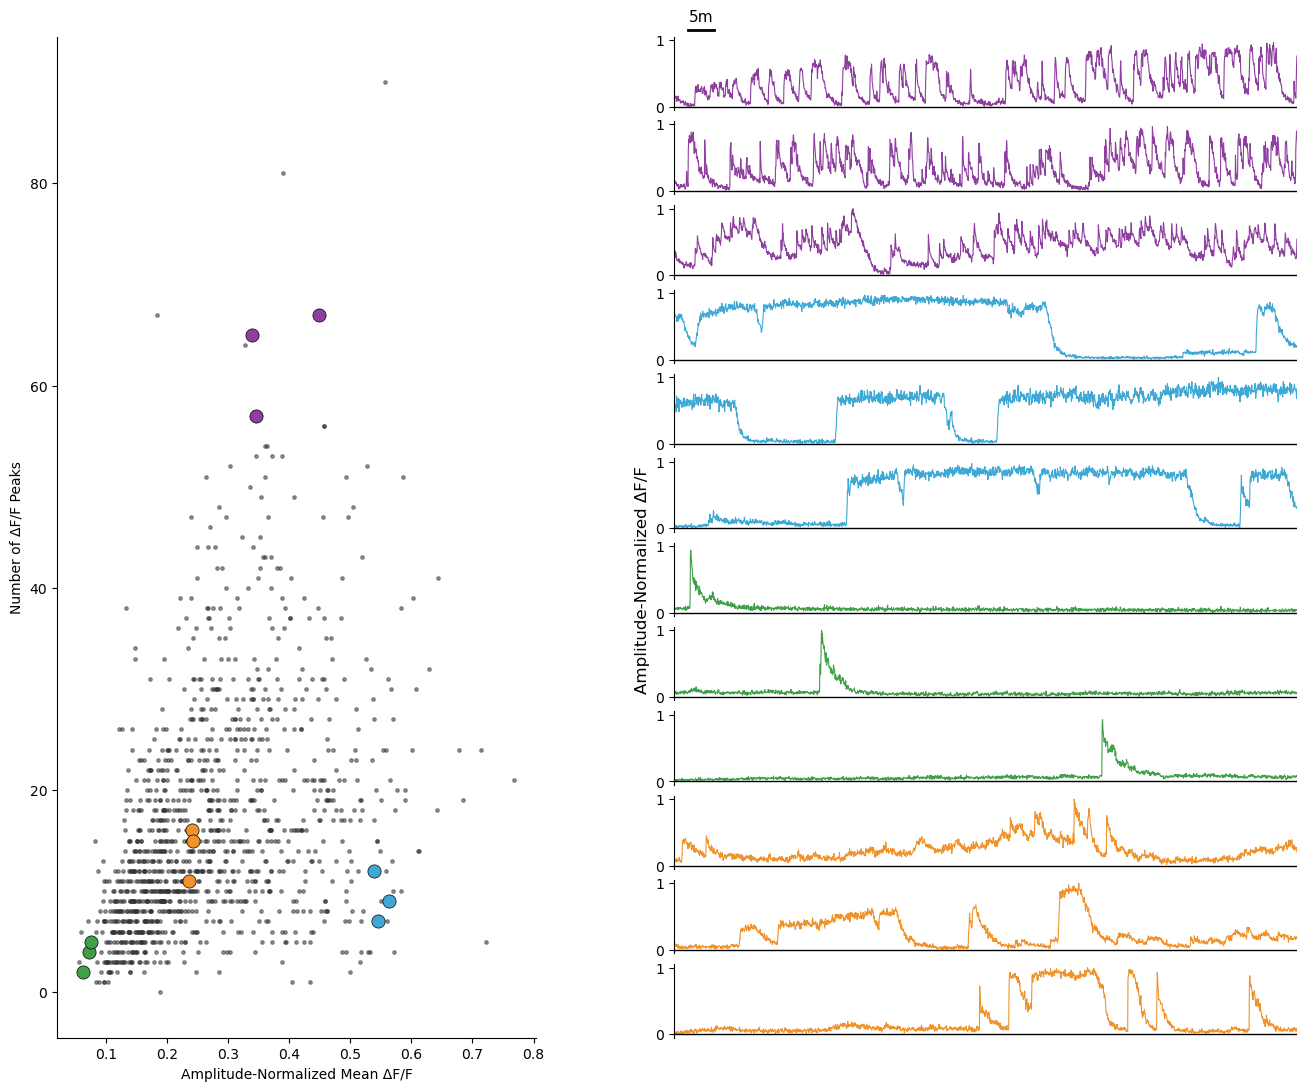

In [5]:
EXAMPLE_CELL_IDS = {'#8e3fa0': [506, 925, 805], '#3fa9d6': [1125, 1010, 998], '#3fa049': [935, 494, 837], '#f0932b': [348, 852, 992]}
fig = activity_space_examples(feat_df, cells, traces, DATASET, EXAMPLE_CELL_IDS, FI,
                              f"{FIG}/Fig2EF_activity_space_and_example_traces")

## Panels G–H

   ant  n_cells  n_total_pairs  n_artifact_pairs  pct_excluded
Ant #1      291          42195               579      1.372200
Ant #2      179          15931               258      1.619484
Ant #3      224          24976               306      1.225176
Ant #4      237          27966               376      1.344490
Ant #5      303          45753               577      1.261119
total: 2096 of 156821 pairs excluded (1.34%)


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


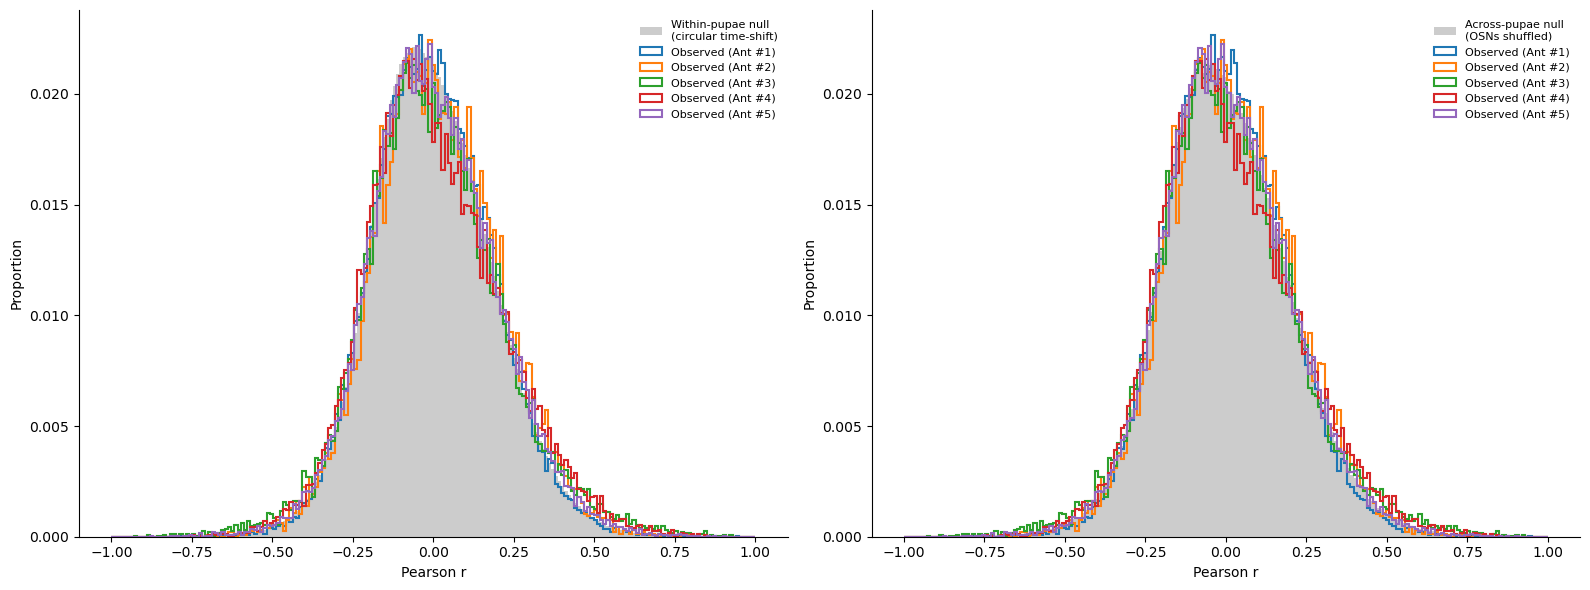

In [6]:
group = load_animal_group(DATASET, cells, qc, coords)
print(group["pairs"].to_string(index=False))
print(f"total: {group['pairs'].n_artifact_pairs.sum()} of {group['pairs'].n_total_pairs.sum()} pairs excluded "
      f"({100 * group['pairs'].n_artifact_pairs.sum() / group['pairs'].n_total_pairs.sum():.2f}%)")
fig = pairwise_r_distributions(group, DATASET, FI, f"{FIG}/Fig2GH_pairwise_r_distributions")